# Шаг 1. Картинка — это массив чисел NumPy

Для компьютера фотография — это не «труба на подставке», а **таблица чисел**.
OpenCV загружает картинку в массив NumPy формы `(высота, ширина, 3)`:
- строка массива — это строка пикселей (координата `y`);
- столбец — это столбец пикселей (координата `x`);
- три числа в каждой ячейке — яркость **синего, зелёного и красного** каналов (порядок **B, G, R**!), каждое от 0 до 255.

Раз картинка — массив, то всё, что умеет NumPy, работает и с картинками:
индексация достаёт пиксель, срез вырезает кусок, присваивание меняет цвет.

**Структура ноутбука (алгоритм):**
1. Импортируем OpenCV и помощники из `common.py`.
2. Загружаем фото трубы и изучаем свойства массива: тип, форму, тип чисел, размер.
3. Читаем значение одного пикселя по координатам `(x, y)`.
4. Срезом массива вырезаем область с маркировкой.
5. Меняем числа в массиве — и видим, как меняется картинка.
6. Разделяем картинку на три канала B, G, R и считаем их среднюю яркость.
7. Показываем результаты и сохраняем вырезанный кусок в `crop.jpg`.

In [ ]:
# Настройка для Google Colab. На своём компьютере эта ячейка ничего не делает.
# В Colab нужна папка machine_vision на Google Диске (в ней session01–session05 и dataset).
import os
import sys

try:
    from google.colab import drive
except ImportError:
    drive = None

if drive:
    drive.mount("/content/drive")
    COLAB_ROOT = "/content/drive/MyDrive/machine_vision"
    os.chdir(f"{COLAB_ROOT}/session02")  # здесь лежит common.py и сохраняются результаты
    sys.path.insert(0, os.getcwd())

## 1. Импорт библиотек и общих помощников

- `cv2` — библиотека **OpenCV**: чтение, обработка и показ изображений.
- `numpy` (`np`) — работа с массивами чисел. Картинка в OpenCV — это и есть массив NumPy.
- `common` — наш модуль из этой же папки (`common.py`) с маленькими помощниками:

| Имя | Что делает |
|-----|------------|
| `PIPE` | путь к фотографии трубы из датасета (`dataset/images/train/...`) |
| `load(path)` | прочитать картинку (работает и с русскими буквами в пути) |
| `save(path, img)` | сохранить картинку в файл |
| `show_nb(img)` | показать картинку прямо в ноутбуке, под ячейкой |
| `label(img, text)` | подписать картинку чёрной полосой сверху (только латиница) |
| `grid(images, cols)` | склеить несколько картинок одинакового размера в таблицу |
| `fit(img, w, h)` | уменьшить картинку, если она не влезает в заданный размер |

> Ноутбук нужно запускать из папки `session02`, иначе `import common` не найдёт модуль.

In [1]:
import cv2

from common import PIPE, load, save, show_nb

## 2. Загружаем картинку и смотрим на её свойства

`load(PIPE)` читает файл и возвращает массив `numpy.ndarray`. Посмотрим на него:

| Свойство | Что означает |
|----------|--------------|
| `type(img)` | тип объекта — обычный массив NumPy |
| `img.shape` | форма: `(высота, ширина, число каналов)` |
| `img.dtype` | тип чисел: `uint8` — целые без знака от 0 до 255 (один байт) |
| `img.size` | сколько всего чисел: высота × ширина × 3 |

Тип: <class 'numpy.ndarray'>
Форма (высота, ширина, каналы): (1080, 1920, 3)
Тип чисел: uint8 — каждое число от 0 до 255
Всего чисел в картинке: 6220800


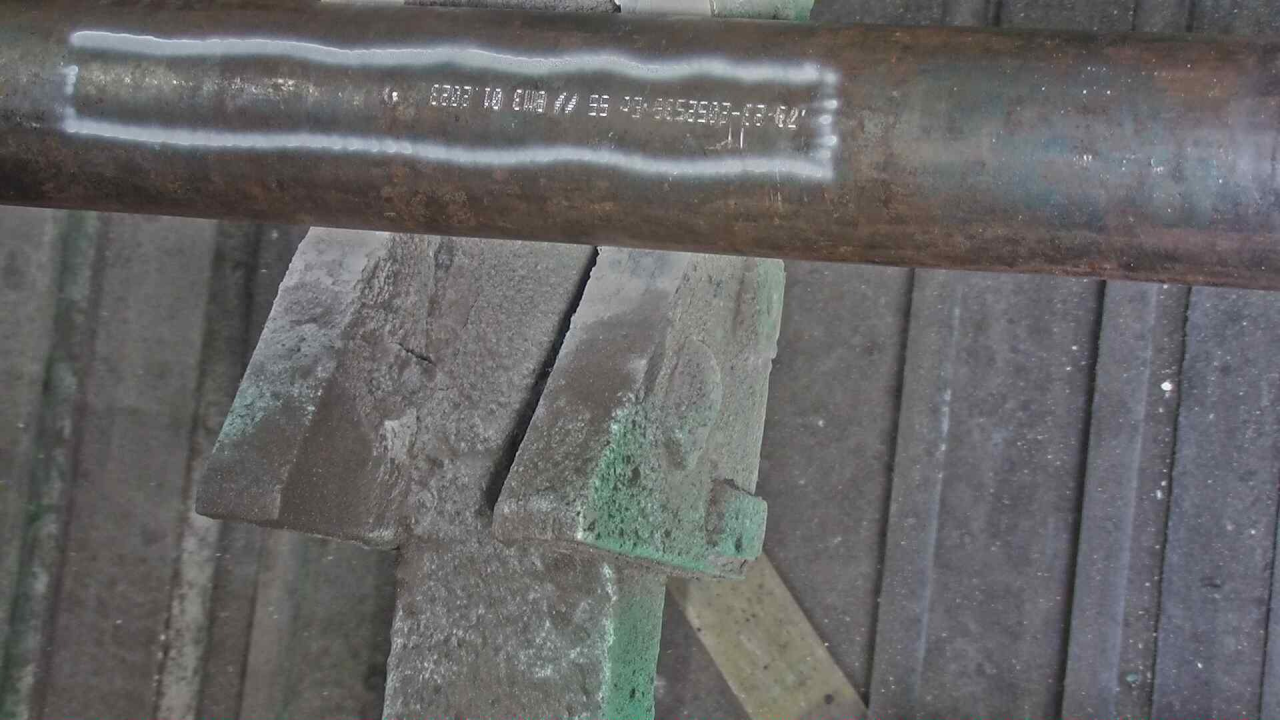

In [2]:
img = load(PIPE)

print("Тип:", type(img))
print("Форма (высота, ширина, каналы):", img.shape)
print("Тип чисел:", img.dtype, "— каждое число от 0 до 255")
print("Всего чисел в картинке:", img.size)

show_nb(img)

## 3. Один пиксель — три числа

Обращение к элементу массива: `img[y, x]` — **сначала строка (y), потом столбец (x)**.
Это частая ошибка: в математике пишут `(x, y)`, а в массиве — `[y, x]`.

Результат — три числа. Внимание: OpenCV хранит цвета в порядке **B, G, R**, а не привычном R, G, B.
Мы берём точку на зелёной краске подставки, поэтому зелёный канал должен быть самым большим.

In [3]:
# Один пиксель — три числа. Внимание: OpenCV хранит цвета в порядке B, G, R
y, x = 760, 1000  # точка на зелёной краске подставки
blue, green, red = img[y, x]
print(f"Пиксель ({x}, {y}): синий={blue}, зелёный={green}, красный={red}")

Пиксель (1000, 760): синий=92, зелёный=102, красный=89


## 4. Срез массива = вырезать кусок картинки

Срез `img[y1:y2, x1:x2]` выбирает строки с `y1` по `y2` и столбцы с `x1` по `x2` (правая граница не включается).
Получается новая картинка — прямоугольник 150 × 700 пикселей с маркировкой трубы.

> Срез в NumPy — это **представление** (view), а не копия: если изменить `crop`, изменится и `img`.

Кусок с маркировкой: (150, 700, 3)


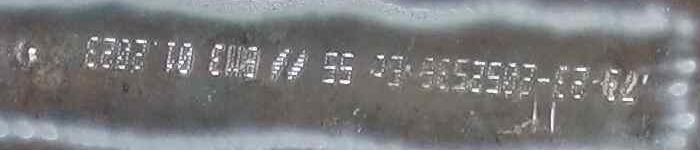

In [4]:
# Срез массива = вырезать кусок картинки: [строки y, столбцы x]
crop = img[90:240, 560:1260]
print("Кусок с маркировкой:", crop.shape)
show_nb(crop)

## 5. Изменить числа = изменить картинку

Чтобы не испортить оригинал, сначала делаем копию `img.copy()`.
Затем в области маркировки ставим **красный канал** (индекс `2`, ведь порядок B=0, G=1, R=2) в максимум 255.
Синий и зелёный остаются прежними — область становится красноватой.

Третий индекс в `marked[y1:y2, x1:x2, 2]` — это номер канала.

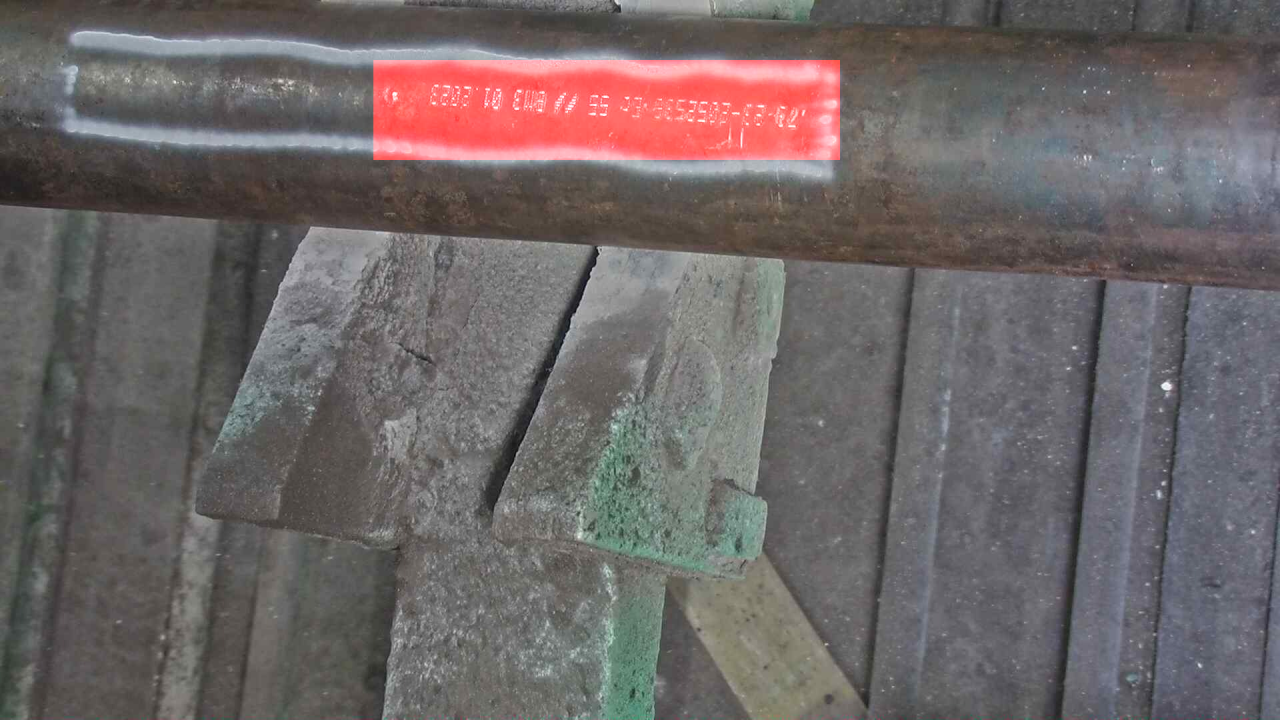

In [5]:
# Изменить числа = изменить картинку
marked = img.copy()
marked[90:240, 560:1260, 2] = 255  # канал 2 (красный) в области маркировки на максимум
show_nb(marked)

## 6. Каналы по отдельности

`cv2.split(img)` разделяет трёхканальную картинку на три отдельных массива `b`, `g`, `r` формы `(высота, ширина)`.
Каждый из них — **серая картинка**: чем светлее пиксель, тем больше этого цвета в исходном пикселе.

Метод `.mean()` считает среднее значение по всем пикселям — среднюю яркость канала.

Средняя яркость каналов B, G, R: 102 101 102


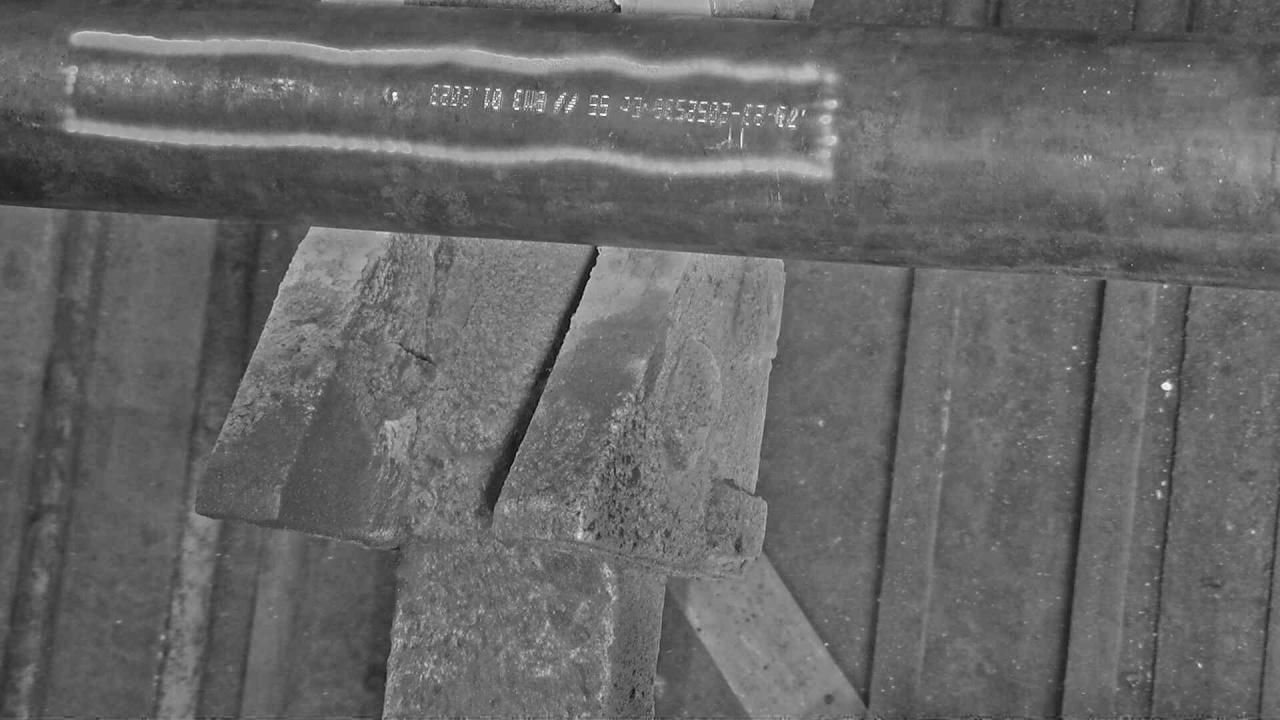

In [6]:
# Каналы по отдельности: каждый — серая картинка
b, g, r = cv2.split(img)
print("Средняя яркость каналов B, G, R:", int(b.mean()), int(g.mean()), int(r.mean()))
show_nb(r)  # красный канал: светлые места — там, где много красного

## 7. Сохраняем результат

`save()` записывает вырезанный кусок маркировки в файл `crop.jpg` — он пригодится в следующих шагах.

In [7]:
save("crop.jpg", crop)

Сохранено: crop.jpg


## Попробуйте сами

1. Возьмите пиксель на ржавой части трубы. Какой канал там самый большой?
2. Поменяйте в шаге 5 канал `2` на `0` или `1`. Что получится?
3. Сделайте `marked[90:240, 560:1260] = 0` — без номера канала. Что произошло и почему?
4. Покажите синий и зелёный каналы. На каком из них маркировка контрастнее?